# Fase 1: comparação dos modelos de priorização

Este notebook gera a base mockada de tarefas, treina os três algoritmos previstos na seção 6.5 do TCC (Regressão Logística, Árvore de Decisão e Random Forest) e compara os resultados.

- **Base:** 3.000 tarefas sintéticas, rotuladas pela regra `S = 0,45·U + 0,35·I + 0,10·C + 0,10·R`, com 10% dos rótulos trocados para uma classe vizinha.
- **Protocolo:** divisão estratificada 80/20, busca de hiperparâmetros com validação cruzada de 5 dobras (F1 macro), avaliação final no conjunto de teste.
- **Linhas de base:** prever sempre a classe majoritária, e a própria regra sem ruído (o teto possível com 10% de ruído).

In [1]:
import sys
import tempfile
from pathlib import Path

RAIZ = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ / "ml" / "training"))

import matplotlib.pyplot as plt
import pandas as pd

from treino.gerador import gerar_tarefas
from treino.treinar import treinar

pd.set_option("display.precision", 3)
%matplotlib inline

## 1. Base mockada

In [2]:
tarefas = gerar_tarefas(n=3000, semente=42)
tarefas.head()

,dias_ate_prazo,impacto,complexidade,esforco_estimado,categoria,prioridade_regra,prioridade
0,14,4,1,0.25,trabalho,media,media
1,17,2,4,0.50,casa,baixa,media
2,3,3,3,7.75,trabalho,alta,media
3,16,4,5,1.00,casa,media,media
4,30,4,2,1.75,casa,baixa,baixa


In [3]:
tarefas.describe()

,dias_ate_prazo,impacto,complexidade,esforco_estimado
count,3000.000,3000.000,3000.000,3000.000
mean,10.924,3.113,2.875,3.043
std,9.759,1.157,1.218,3.059
min,0.000,1.000,1.000,0.250
25%,4.000,2.000,2.000,1.250
50%,7.000,3.000,3.000,2.250
75%,14.000,4.000,4.000,3.750
max,47.000,5.000,5.000,40.000


In [4]:
distribuicao = pd.DataFrame(
    {
        "regra sem ruído": tarefas["prioridade_regra"].value_counts(),
        "rótulo final": tarefas["prioridade"].value_counts(),
    }
).loc[["baixa", "media", "alta"]]
print(
    f"Rótulos trocados pelo ruído: {(tarefas['prioridade'] != tarefas['prioridade_regra']).mean():.1%}"
)
distribuicao

Rótulos trocados pelo ruído: 9.8%


,regra sem ruído,rótulo final
baixa,959,915
media,1019,1125
alta,1022,960


## 2. Treino e comparação

In [5]:
saida = Path(tempfile.mkdtemp())
resultados = treinar(
    n=3000, semente=42, versao="notebook", dir_modelos=saida, dir_resultados=saida, csv=None
)

linhas = []
for nome, m in resultados["linhas_de_base"].items():
    linhas.append(
        {
            "modelo": nome,
            "tipo": "linha de base",
            "f1_validacao": None,
            "acuracia": m["acuracia"],
            "f1_macro": m["f1_macro"],
        }
    )
for nome, r in resultados["modelos"].items():
    linhas.append(
        {
            "modelo": nome,
            "tipo": "algoritmo",
            "f1_validacao": r["f1_macro_validacao"],
            "acuracia": r["teste"]["acuracia"],
            "f1_macro": r["teste"]["f1_macro"],
        }
    )
comparacao = pd.DataFrame(linhas).set_index("modelo")
print("Escolhido pela validação cruzada:", resultados["escolhido"])
comparacao

Escolhido pela validação cruzada: Árvore de Decisão


,tipo,f1_validacao,acuracia,f1_macro
modelo,,,,
Classe majoritária,linha de base,NaN,0.375,0.182
Regra sem ruído,linha de base,NaN,0.905,0.906
Regressão Logística,algoritmo,0.775,0.742,0.746
Árvore de Decisão,algoritmo,0.851,0.853,0.856
Random Forest,algoritmo,0.846,0.847,0.849


In [6]:
pd.DataFrame({nome: r["melhores_parametros"] for nome, r in resultados["modelos"].items()}).T

,C,max_depth,min_samples_leaf,n_estimators
Regressão Logística,10.0,NaN,NaN,NaN
Árvore de Decisão,NaN,NaN,5.0,NaN
Random Forest,NaN,NaN,5.0,100.0


## 3. Desempenho por classe

In [7]:
pd.DataFrame(
    {
        (nome, classe): valores
        for nome, r in resultados["modelos"].items()
        for classe, valores in r["teste"]["por_classe"].items()
    }
).T

precision  recall  f1-score
Regressão Logística baixa      0.765   0.694     0.728
                    media      0.652   0.707     0.678
                    alta       0.837   0.828     0.833
Árvore de Decisão   baixa      0.851   0.902     0.875
                    media      0.831   0.764     0.796
                    alta       0.879   0.911     0.895
Random Forest       baixa      0.861   0.880     0.870
                    media      0.812   0.769     0.790
                    alta       0.870   0.906     0.888

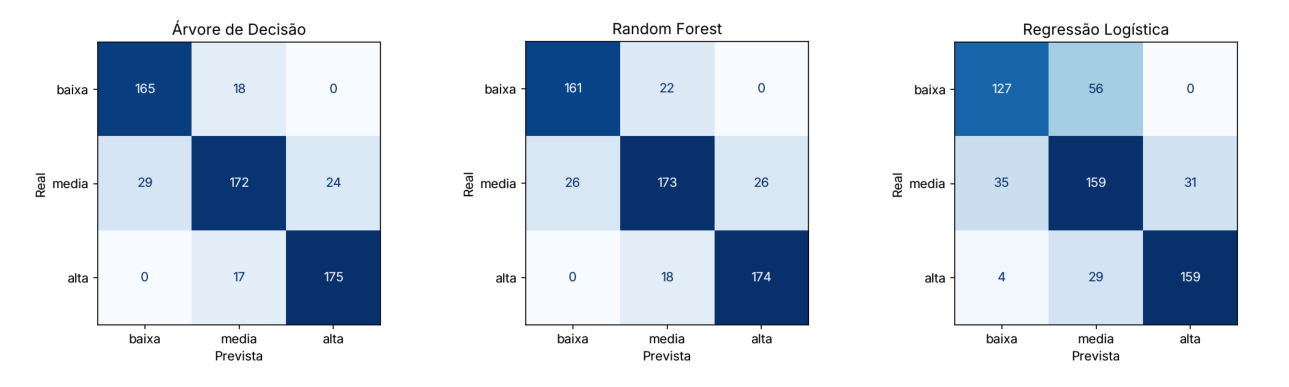

In [8]:
from PIL import Image

fig, eixos = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, arquivo in zip(eixos, sorted(saida.glob("matriz-*.png")), strict=True):
    ax.imshow(Image.open(arquivo))
    ax.axis("off")
fig.tight_layout()

## 4. O que pesa na prioridade

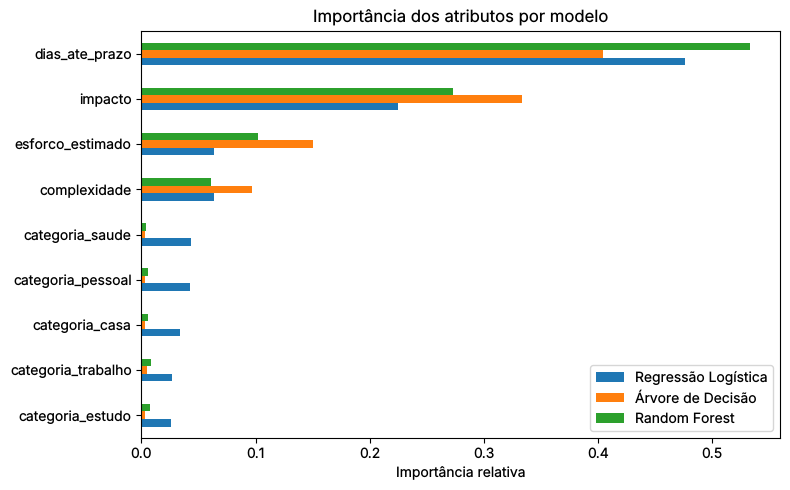

In [9]:
importancias = pd.DataFrame(
    {nome: r["importancia_atributos"] for nome, r in resultados["modelos"].items()}
).fillna(0)
importancias = importancias.loc[importancias.max(axis=1).sort_values().index]
ax = importancias.plot.barh(figsize=(8, 5))
ax.set_xlabel("Importância relativa")
ax.set_title("Importância dos atributos por modelo")
plt.tight_layout()

## 5. Leitura dos resultados

- Os três algoritmos superam com folga a linha de base da classe majoritária.
- Com 10% de ruído, nenhum modelo passa muito da regra sem ruído, que é o teto prático. A Árvore de Decisão e a Random Forest ficam perto desse teto; a Regressão Logística fica abaixo, porque a urgência muda em degraus conforme o prazo e um modelo linear aproxima mal esses degraus.
- A classe **média** é a mais difícil: ela recebe ruído dos dois lados e fica entre as outras duas.
- **Prazo** e **impacto** são os atributos mais importantes, coerente com os pesos da regra (45% e 35%). A categoria quase não pesa, porque a regra não a usa.
- **Limitação:** com dados sintéticos, a acurácia mede o quanto o modelo recupera a regra, não o julgamento de pessoas reais. A comparação antes e depois do retreino com os ajustes dos participantes (fase 6) é o que vai mostrar o ganho de personalização.